# Occupancy of the nose: where do mice point their noses while searching?

`occupancy_centroid.ipynb` again, with the SLEAP **nose** in place of the body centroid. The nose is what the task cares about - a target is found when the nose enters its cell - so these maps show where the mouse is *checking*, where the centroid maps show where its body is. The same three questions:

1. **Do mice differ?** Does each mouse have its own map, and do some dwell in particular places?
2. **What changes with experience?** Each mouse's last three sessions minus its first three.
3. **What is different about a good session?** Each mouse's sessions with the most targets found minus those with the fewest.

**The maps.** The arena is cut into 20 x 44 bins, a quarter of a target cell on a side. A map shows **relative occupancy**: the share of **search** time the nose spends in a bin, divided by the share it would get if the mouse spread its time uniformly over the whole frame. So **1 means exactly its fair share, 2 means twice as much time as a uniform spread would put there, 0.5 half as much**. A difference map is one relative-occupancy map minus another.

**Search** means the **appetitive** epoch: from the mouse leaving the port after one reward until it finds the next target. The other two epochs, **consummatory** (target found, until the mouse pokes a port) and **drinking** (at the port), are shown once in section 1 and left out after that.

**Reading them.** The arena is drawn on its side: the long axis runs left to right, low-y end on the left. The thin rectangle is the edge of the 3 x 9 grid of target cells, and the two short lines mark the middle row, where the ports are. Outside the rectangle is the grid's outer ring, one cell wide, which never holds a target: a nose out there is not checking anything.

**Zones.** Defined exactly as in the centroid notebook, from the area the tracked point reaches, so the two notebooks can be read side by side. Unlike the body, the nose reaches almost the whole frame.

- **wall lane** - within three quarters of a cell (133 px) of the edge of the reachable area. For the nose this is most of the grid's outer ring: the nose is at a wall.
- **at the ports** - the bins the nose is in while the mouse drinks. A search starts with the mouse leaving a port.
- **interior** - everything else the nose can reach, which is the target grid plus a thin margin.
- **outside the target grid** - the grid's outer ring as the task defines it (not a separate zone: it overlaps the wall lane and the ports). This one is specific to the nose notebook.

**A caution about search occupancy.** A search ends at the target, so occupancy during search is pulled toward wherever targets are. Here every comparison is between sessions or mice that have the same mix of target locations, so the pull is the same on both sides and cancels.

The SLEAP nose is tracked less cleanly than the centroid (a jump of more than 150 px between frames on 0.2-0.8% of frames, against almost none), which adds a little scatter to these maps.

Odor `x` and vision `v` sessions, each mouse's first ten of each (mouse 9000 has six vision sessions).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import stats as sps

from src import config as cfg
from src.trials import load_trials
from src.epochs import EPOCHS
from src.occupancy import load_occupancy, X_EDGES, Y_EDGES     # run `python -m src.occupancy` to rebuild output/occupancy*.npz

pd.set_option('display.width', 200, 'display.precision', 3)

EXPERIMENTS = ['odor', 'vision']
EXP_COLOR = {'odor': '#2a78d6', 'vision': '#7a52c7'}
EXP_LABEL = {'odor': 'Odor', 'vision': 'Vision'}
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'legend.frameon': False, 'figure.dpi': 110,
})

POINT = 'nose'
loaded = [load_occupancy(e, POINT) for e in EXPERIMENTS]
ses = pd.concat([l[0] for l in loaded], ignore_index=True)            # one row per session, aligned with the maps
maps = {epoch: np.concatenate([l[1][epoch] for l in loaded]) for epoch in EPOCHS}     # {epoch: [session, y bin, x bin]}, seconds
search_s = maps['appetitive']                                         # the search: leaving the port to finding the target

def density(maps):
    """Share of time per bin, scaled so 1 = time spread evenly over the arena."""
    return maps / maps.sum(axis=(-2, -1), keepdims=True) * maps.shape[-2] * maps.shape[-1]

D = density(search_s)
RELATIVE = 'relative occupancy (1 = uniform)'      # label for the color scale
MICE = sorted(ses.mouse.unique())

finds = pd.concat([load_trials(e).assign(experiment=e) for e in EXPERIMENTS]).groupby(['experiment', 'mouse', 'session']).size().rename('finds')
ses = ses.join(finds, on=['experiment', 'mouse', 'session'])
ses['n_sessions'] = ses.groupby(['experiment', 'mouse']).session_num.transform('max')

# where each bin is, relative to the area the nose actually reaches
xc, yc = (X_EDGES[:-1] + X_EDGES[1:]) / 2, (Y_EDGES[:-1] + Y_EDGES[1:]) / 2
XX, YY = np.meshgrid(xc, yc)
pooled = density(sum(maps.values()).sum(axis=0))
reach_x, reach_y = xc[pooled.mean(axis=0) > 0.05], yc[pooled.mean(axis=1) > 0.05]
half_x, half_y = np.diff(X_EDGES)[0] / 2, np.diff(Y_EDGES)[0] / 2
REACH = dict(x0=reach_x.min() - half_x, x1=reach_x.max() + half_x, y0=reach_y.min() - half_y, y1=reach_y.max() + half_y)
to_end = np.minimum(YY - REACH['y0'], REACH['y1'] - YY)
wall_dist = np.minimum(np.minimum(XX - REACH['x0'], REACH['x1'] - XX), to_end)       # px inside the reachable edge; negative = outside
LANE = 0.75 * cfg.CELL_W
lane = (wall_dist > 0) & (wall_dist < LANE)
ports = density(maps['drinking'].sum(axis=0)) > 10   # the bins the nose is in while the mouse drinks
ZONES = {'wall lane': lane & ~ports, '   along the side walls': lane & (to_end >= LANE) & ~ports, '   along the end walls': lane & (to_end < LANE) & ~ports,
         'at the ports': ports, 'interior': (wall_dist >= LANE) & ~ports,
         'outside the target grid': ((XX < cfg.CELL_W) | (XX >= cfg.FRAME_W - cfg.CELL_W) | (YY < cfg.CELL_H) | (YY >= cfg.FRAME_H - cfg.CELL_H))}
print('reachable area (px):', {k: round(v) for k, v in REACH.items()}, '| bins:', {name.strip(): int(mask.sum()) for name, mask in ZONES.items()})
zone_share = pd.DataFrame({name: search_s[:, mask].sum(axis=1) / search_s.sum(axis=(1, 2)) for name, mask in ZONES.items()})

def show(ax, m, cmap='magma', vmin=0, vmax=3, title=None, lines='#fcfcfb'):
    """Draw one map with the arena on its side: long axis left to right, low-y end on the left."""
    im = ax.imshow(m.T, origin='lower', extent=(0, cfg.FRAME_H, 0, cfg.FRAME_W), cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.add_patch(Rectangle((cfg.CELL_H, cfg.CELL_W), cfg.FRAME_H - 2 * cfg.CELL_H, cfg.FRAME_W - 2 * cfg.CELL_W, fill=False, edgecolor=lines, lw=0.6))
    for y in (cfg.LOW_MAX_Y, cfg.HIGH_MIN_Y):
        ax.plot([y, y], [cfg.CELL_W, cfg.CELL_W + 60], color=lines, lw=0.6)
        ax.plot([y, y], [cfg.FRAME_W - cfg.CELL_W - 60, cfg.FRAME_W - cfg.CELL_W], color=lines, lw=0.6)
    ax.set(xticks=[], yticks=[])
    for side in ax.spines.values():
        side.set_visible(False)
    if title is not None:
        ax.set_title(title, fontsize=8, fontweight='normal', pad=2)
    return im

def colorbar(fig, im, axes, label):
    cb = fig.colorbar(im, ax=axes, shrink=0.7, pad=0.01, aspect=30)
    cb.set_label(label, fontsize=8); cb.ax.tick_params(labelsize=7); cb.outline.set_visible(False)

reachable area (px): {'x0': 0, 'x1': 888, 'y0': 45, 'y1': 1923} | bins: {'wall lane': 331, 'along the side walls': 211, 'along the end walls': 120, 'at the ports': 5, 'interior': 504, 'outside the target grid': 448}


## 1. The average map, by epoch

The session is divided into the three epochs used in the lab's cluster-states-viewer:

- **appetitive** - the search: from leaving the port after one reward until the next target is found (the ITI is part of it).
- **consummatory** - target found, until the mouse pokes a port.
- **drinking** - at the port, from that poke until the ITI begins, counting only frames within half a second of a poke.

Each map is scaled to its own epoch's time, so the three rows are directly comparable in shape even though the epochs differ greatly in length. Drinking has its own color scale because it is all at the ports.

experiment,odor,vision
mice,9.000,9.000
sessions,90.000,86.000
appetitive time per session (min),33.166,31.999
consummatory time per session (min),3.116,2.902
drinking time per session (min),7.472,8.267
share of search time: wall lane,0.313,0.265
share of search time: along the side walls,0.122,0.095
share of search time: along the end walls,0.191,0.170
share of search time: at the ports,0.023,0.016
share of search time: interior,0.662,0.717


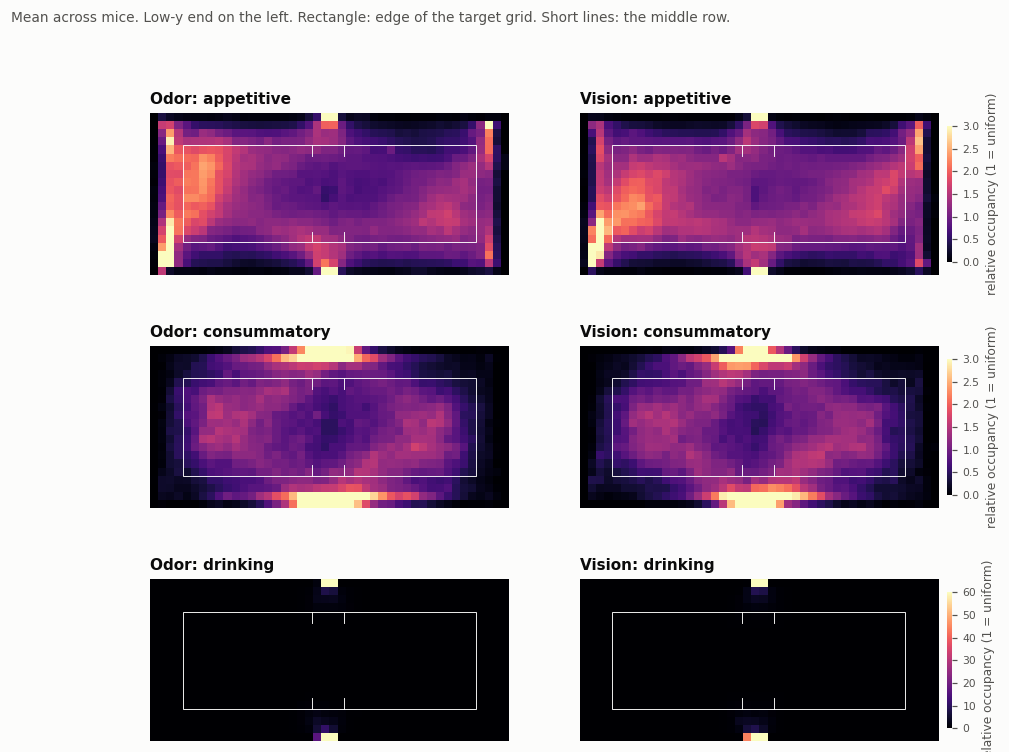

In [2]:
overview = ses.groupby('experiment').agg(mice=('mouse', 'nunique'), sessions=('session', 'size'))
for epoch in EPOCHS:
    overview[f'{epoch} time per session (min)'] = pd.Series(maps[epoch].sum(axis=(1, 2)) / 60).groupby(ses.experiment).mean()
display(overview.join(zone_share.groupby(ses.experiment).mean().add_prefix('share of search time: ')).loc[EXPERIMENTS].T)

def mean_over_mice(maps, keep):
    """Mean map across mice of each mouse's mean map over its sessions in `keep`."""
    return np.mean([maps[g.index].mean(axis=0) for _, g in ses[keep].groupby('mouse')], axis=0)

EPOCH_VMAX = {'appetitive': 3, 'consummatory': 3, 'drinking': 60}      # drinking is all at the ports, so it needs its own scale
fig, axes = plt.subplots(len(EPOCHS), 2, figsize=(11, 7.8))
for row, epoch in zip(axes, EPOCHS):
    for ax, exp in zip(row, EXPERIMENTS):
        im = show(ax, mean_over_mice(density(maps[epoch]), ses.experiment == exp), vmax=EPOCH_VMAX[epoch])
        ax.set_title(f'{EXP_LABEL[exp]}: {epoch}', fontsize=10, fontweight='bold')
    colorbar(fig, im, row, RELATIVE)
fig.suptitle('Mean across mice. Low-y end on the left. Rectangle: edge of the target grid. Short lines: the middle row.', x=0.01, ha='left', fontsize=9, color=MUTED)
plt.show()

**How the session divides.** Per session, mice spend about 33 minutes searching (appetitive), 3 minutes in the consummatory epoch and 7-8 minutes drinking.

**Appetitive: the nose spends a large part of every search where no target can be.** 42% of search time in the odor sessions and 36% in vision is spent with the nose outside the target grid, in the outer ring. Nearly half of that is beyond the last row at either end (19% and 17% of search time), where the brightest parts of the map are: the nose is against an end wall. The rest is along the side walls and at the ports. Inside the grid the nose is spread fairly evenly, with more time toward the two ends than in the middle and the most just inside the low-y end.

By the zones shared with the centroid notebook: the wall lane holds 31% of search time in odor and 27% in vision, the interior 66% and 72%, the ports 2% in both.

**Consummatory.** From wherever the target was found - the two halves of the grid - to the ports, where the map is brightest.

**Drinking.** The nose is in a port.

## 2. Every session of every mouse

One row per mouse, one column per session (its 1st to 10th of the experiment). The color scale is the same in every panel. Each title gives the session and the number of targets found in it.

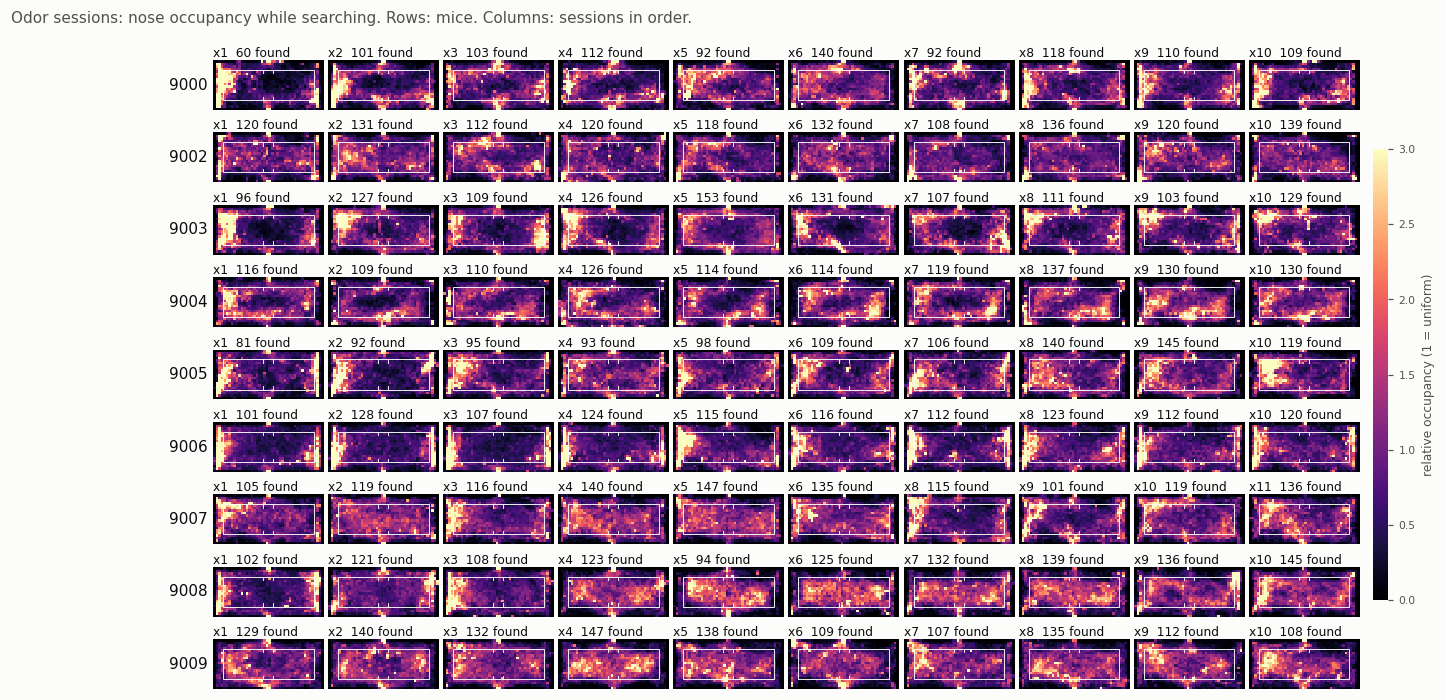

In [3]:
def session_grid(exp):
    fig, axes = plt.subplots(len(MICE), 10, figsize=(16, 7.6), gridspec_kw={'wspace': 0.04, 'hspace': 0.12})
    for row, mouse in zip(axes, MICE):
        for n, ax in enumerate(row, start=1):
            hit = ses[(ses.experiment == exp) & (ses.mouse == mouse) & (ses.session_num == n)]
            if len(hit):
                im = show(ax, D[hit.index[0]], title=f"{hit.session.iloc[0]}  {int(hit.finds.iloc[0])} found")
            else:
                ax.axis('off')
        row[0].set_ylabel(mouse, rotation=0, ha='right', va='center', color=INK, fontsize=10)
    colorbar(fig, im, axes, RELATIVE)
    fig.suptitle(f'{EXP_LABEL[exp]} sessions: nose occupancy while searching. Rows: mice. Columns: sessions in order.', x=0.01, y=0.93, ha='left', fontsize=10, color=MUTED)
    plt.show()

session_grid('odor')

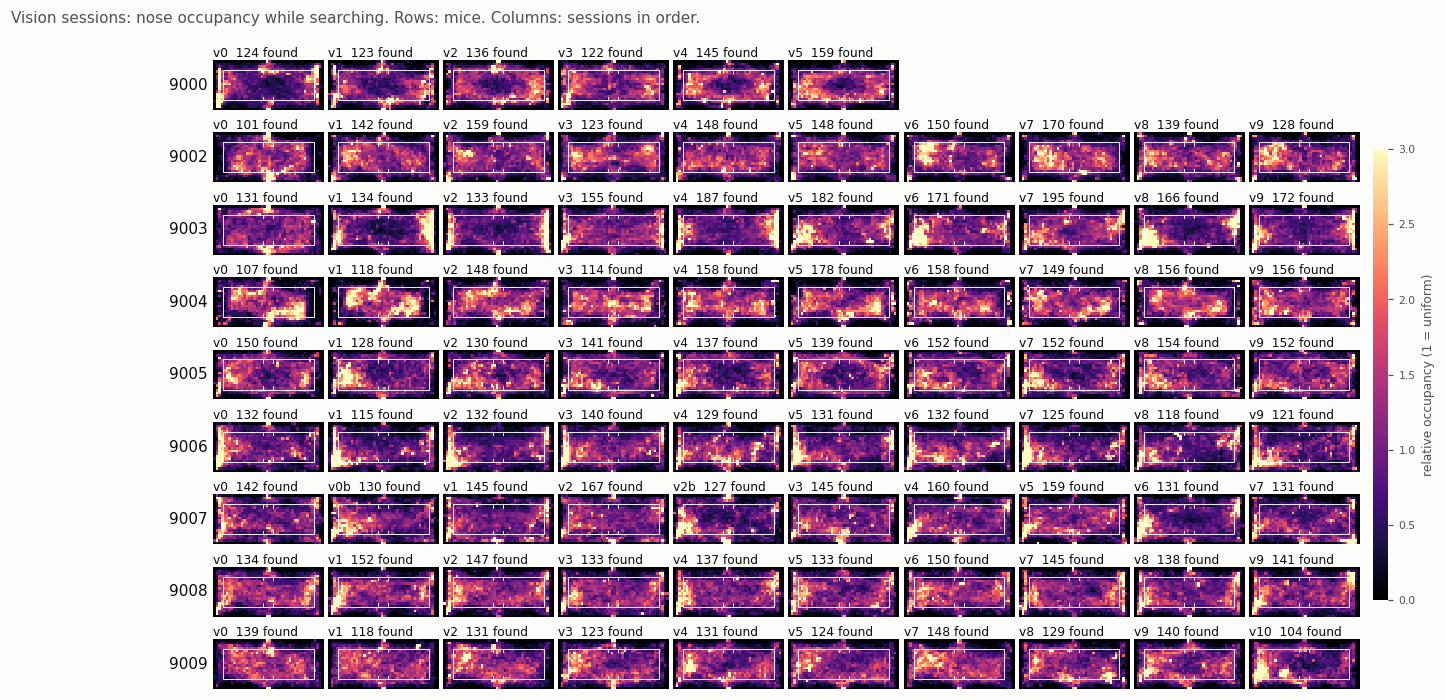

In [4]:
session_grid('vision')

## 3. Do mice differ?

**Each mouse's own map**, averaged over its sessions, and below it the same map **minus the average of all mice** in that experiment: red where this mouse spends more time than mice in general, blue where it spends less.

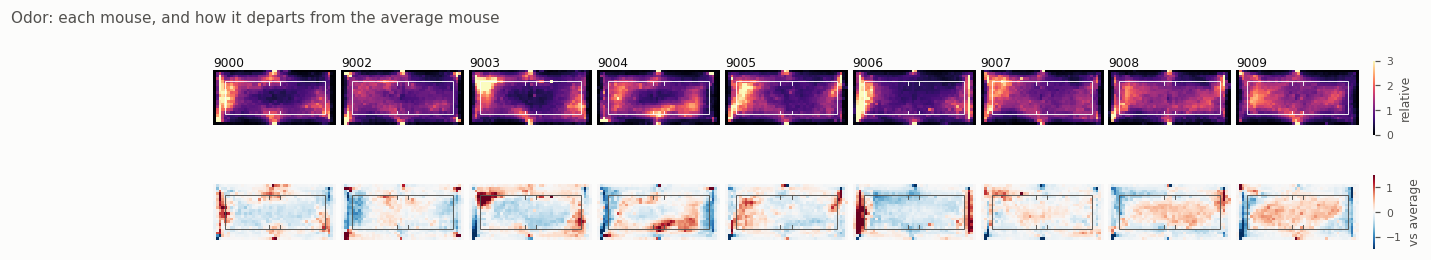

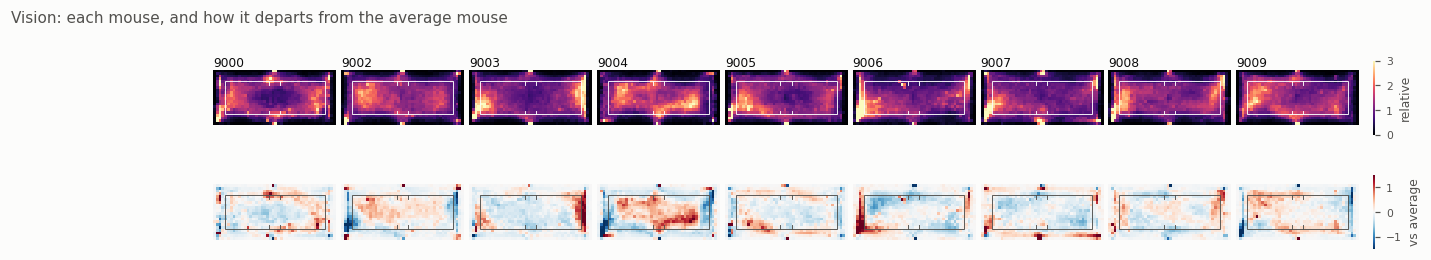

In [5]:
mouse_map = {(exp, m): D[g.index].mean(axis=0) for (exp, m), g in ses.groupby(['experiment', 'mouse'])}
group_map = {exp: np.mean([mouse_map[exp, m] for m in MICE], axis=0) for exp in EXPERIMENTS}

for exp in EXPERIMENTS:
    fig, axes = plt.subplots(2, len(MICE), figsize=(16, 2.6), gridspec_kw={'wspace': 0.04, 'hspace': 0.08})
    for col, m in enumerate(MICE):
        im_a = show(axes[0, col], mouse_map[exp, m], title=m)
        im_b = show(axes[1, col], mouse_map[exp, m] - group_map[exp], cmap='RdBu_r', vmin=-1.5, vmax=1.5, lines=MUTED)
    colorbar(fig, im_a, axes[0], 'relative')
    colorbar(fig, im_b, axes[1], 'vs average')
    fig.suptitle(f'{EXP_LABEL[exp]}: each mouse, and how it departs from the average mouse', x=0.01, y=1.0, ha='left', fontsize=10, color=MUTED)
    plt.show()

**Is a mouse's map its own?** If mice have individual habits, two sessions from the same mouse should look more alike than two sessions from different mice. Similarity here is the correlation between two sessions' maps across bins. The matrix shows it for every pair of sessions, sorted by mouse; blocks along the diagonal are mice that resemble themselves.

The second test is stricter: does a mouse's departure from the average mouse in the odor sessions predict its departure in the vision sessions, weeks later?

,"same mouse, different sessions",different mice,difference,p (paired t),mice more like themselves
Odor,0.563,0.362,0.202,0.0,9/9
Vision,0.597,0.43,0.167,0.0,9/9


departure from the average mouse, odor vs vision: same mouse r = 0.44, different mice r = -0.04, paired p = 0.0010, 9/9 mice more like themselves


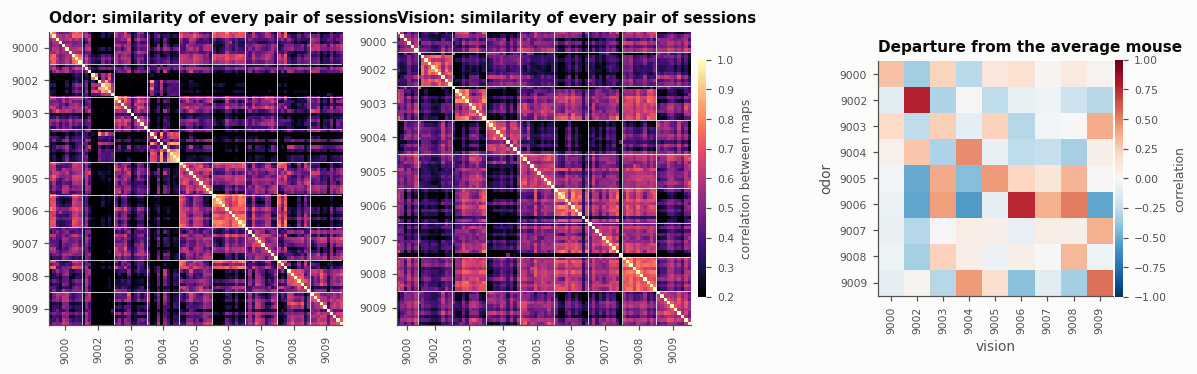

In [6]:
flat = D.reshape(len(D), -1)
similarity = np.corrcoef(flat)
same_exp = ses.experiment.to_numpy()[:, None] == ses.experiment.to_numpy()[None, :]
same_mouse = ses.mouse.to_numpy()[:, None] == ses.mouse.to_numpy()[None, :]
other_session = ~np.eye(len(ses), dtype=bool)

rows = {}
for exp in EXPERIMENTS:
    own, others = {}, {}
    for m, g in ses[ses.experiment == exp].groupby('mouse'):
        i = g.index.to_numpy()
        own[m] = similarity[np.ix_(i, i)][other_session[np.ix_(i, i)]].mean()
        others[m] = similarity[i][:, (same_exp[i[0]] & ~same_mouse[i[0]])].mean()
    own, others = pd.Series(own), pd.Series(others)
    rows[EXP_LABEL[exp]] = {'same mouse, different sessions': own.mean(), 'different mice': others.mean(), 'difference': (own - others).mean(),
                            'p (paired t)': sps.ttest_rel(own, others).pvalue, 'mice more like themselves': f'{int((own > others).sum())}/{len(own)}'}
display(pd.DataFrame(rows).T)

# a mouse's departure from the average mouse, odor against vision
departure = {exp: np.array([(mouse_map[exp, m] - group_map[exp]).ravel() for m in MICE]) for exp in EXPERIMENTS}
across = np.corrcoef(departure['odor'], departure['vision'])[:len(MICE), len(MICE):]       # [odor mouse, vision mouse]
same, different = np.diag(across), (across.sum(axis=1) - np.diag(across)) / (len(MICE) - 1)
print(f"departure from the average mouse, odor vs vision: same mouse r = {same.mean():.2f}, different mice r = {different.mean():.2f}, "
      f"paired p = {sps.ttest_rel(same, different).pvalue:.4f}, {int((same > different).sum())}/{len(MICE)} mice more like themselves")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), gridspec_kw={'width_ratios': [1, 1, 0.8]})
for ax, exp in zip(axes, EXPERIMENTS):
    i = ses.index[ses.experiment == exp].to_numpy()
    im = ax.imshow(similarity[np.ix_(i, i)], cmap='magma', vmin=0.2, vmax=1, interpolation='nearest')
    edges = np.flatnonzero(np.r_[True, ses.mouse[i].to_numpy()[1:] != ses.mouse[i].to_numpy()[:-1], True])
    ax.set(xticks=(edges[:-1] + edges[1:]) / 2 - 0.5, xticklabels=MICE, yticks=(edges[:-1] + edges[1:]) / 2 - 0.5, yticklabels=MICE,
           title=f'{EXP_LABEL[exp]}: similarity of every pair of sessions')
    ax.tick_params(axis='x', rotation=90, labelsize=7); ax.tick_params(axis='y', labelsize=7)
    for e in edges[1:-1]:
        ax.axhline(e - 0.5, color='#fcfcfb', lw=0.5); ax.axvline(e - 0.5, color='#fcfcfb', lw=0.5)
colorbar(fig, im, axes[:2], 'correlation between maps')
im = axes[2].imshow(across, cmap='RdBu_r', vmin=-1, vmax=1, interpolation='nearest')
axes[2].set(xticks=range(len(MICE)), xticklabels=MICE, yticks=range(len(MICE)), yticklabels=MICE, xlabel='vision', ylabel='odor',
            title='Departure from the average mouse')
axes[2].tick_params(axis='x', rotation=90, labelsize=7); axes[2].tick_params(axis='y', labelsize=7)
colorbar(fig, im, axes[2], 'correlation')
plt.show()

**Yes, and the nose maps separate the mice at least as well as the body maps do.**
- Two sessions from the same mouse are more alike than two sessions from different mice: correlation 0.56 against 0.36 in odor, 0.60 against 0.43 in vision, in all nine mice in both. (Centroid maps: 0.60 against 0.44, and 0.63 against 0.49.)
- The individual pattern carries over from odor to vision: a mouse's departure from the average mouse correlates 0.44 with its own departure in the other experiment and -0.04 with other mice's (9/9 mice).

**What the differences look like.**
- Time outside the target grid ranges from 33% (9009) to 53% (9006) of search time in odor, and from 25% (9004) to 44% (9007) in vision.
- 9006 is the extreme: its nose is beyond the end rows for 35% of its search time in odor and 26% in vision, against an average of 17-19%.
- 9004 again has the most distinctive map, with two hot spots inside the grid, and spends the least time outside it in vision.
- The mice whose bodies run the walls are the ones whose noses are outside the grid: across mice the two shares correlate 0.74 in odor and 0.67 in vision.
- Every mouse spends at least half of its search time with its nose in the low-y half of the arena (53-61% in odor, 52-60% in vision).

## 4. With experience: last three sessions minus first three

For each mouse, the mean map of its last three sessions minus the mean map of its first three. Red: more time there late than early. Blue: less. Three comparisons:

- within the odor sessions,
- within the vision sessions,
- across the whole history: the last three vision sessions minus the first three odor sessions.

Three sessions at each end, not four, so that mouse 9000 can be included: it has six vision sessions.

The large maps are the mean across mice. The small ones are each mouse.

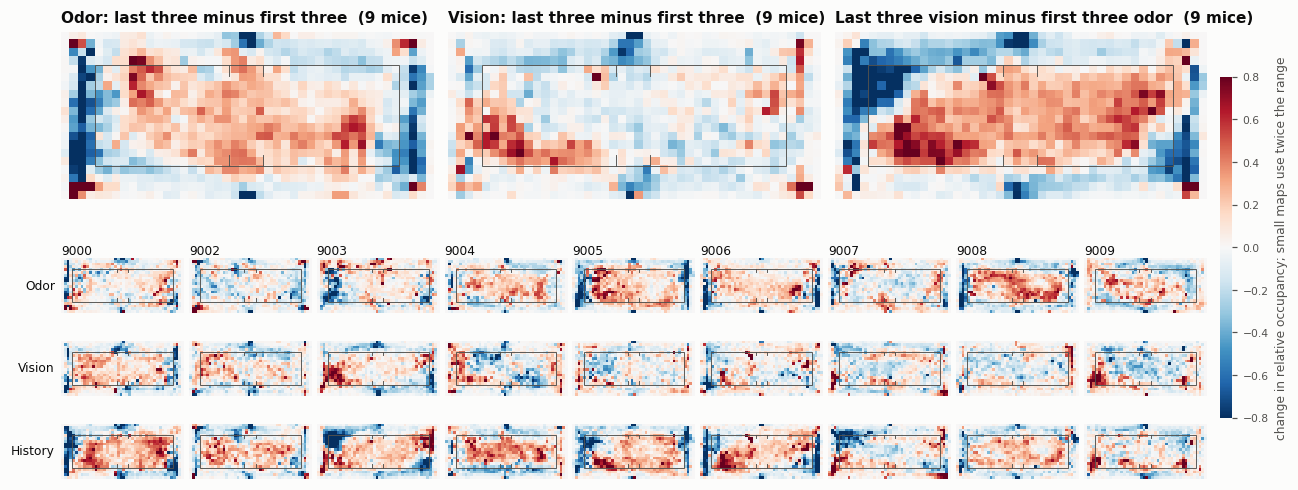

In [7]:
N_ENDS = 3                                         # sessions at each end; every mouse has at least six, so the two never overlap
first = ses.session_num <= N_ENDS
last = ses.session_num > ses.n_sessions - N_ENDS
odor, vision = ses.experiment == 'odor', ses.experiment == 'vision'
CHANGES = {'Odor: last three minus first three': (odor & first, odor & last),
           'Vision: last three minus first three': (vision & first, vision & last),
           'Last three vision minus first three odor': (odor & first, vision & last)}

def per_mouse_maps(keep):
    return {m: D[g.index].mean(axis=0) for m, g in ses[keep].groupby('mouse')}

def difference_maps(before, after):
    """{mouse: after map - before map}, for mice that have both."""
    a, b = per_mouse_maps(before), per_mouse_maps(after)
    return {m: b[m] - a[m] for m in MICE if m in a and m in b}

def difference_figure(contrasts, vlim=0.8):
    fig = plt.figure(figsize=(16, 2.9 + 0.95 * len(contrasts)))
    outer = fig.add_gridspec(2, 1, height_ratios=[2.6, 0.95 * len(contrasts)], hspace=0.08)
    top = outer[0].subgridspec(1, len(contrasts), wspace=0.04)
    bottom = outer[1].subgridspec(len(contrasts), len(MICE), wspace=0.04, hspace=0.05)
    axes = []
    for k, (name, (before, after)) in enumerate(contrasts.items()):
        diffs = difference_maps(before, after)
        ax = fig.add_subplot(top[0, k]); axes.append(ax)
        im = show(ax, np.mean(list(diffs.values()), axis=0), cmap='RdBu_r', vmin=-vlim, vmax=vlim, lines=MUTED)
        ax.set_title(f'{name}  ({len(diffs)} mice)', fontsize=10, fontweight='bold')
        for col, m in enumerate(MICE):
            ax = fig.add_subplot(bottom[k, col]); axes.append(ax)
            if m in diffs:
                show(ax, diffs[m], cmap='RdBu_r', vmin=-vlim * 2, vmax=vlim * 2, lines=MUTED, title=m if k == 0 else None)
            else:
                ax.set(xticks=[], yticks=[])
                for side in ax.spines.values():
                    side.set_visible(False)
            if col == 0:
                ax.set_ylabel(name.split(':')[0] if ':' in name else 'History', rotation=0, ha='right', va='center', fontsize=8, color=INK)
    colorbar(fig, im, axes, 'change in relative occupancy; small maps use twice the range')
    plt.show()

difference_figure(CHANGES)

The same change in numbers: the share of search time in each zone, per mouse, before and after.

In [8]:
def zone_change(before, after):
    a = zone_share[before].groupby(ses.mouse[before]).mean()
    b = zone_share[after].groupby(ses.mouse[after]).mean()
    a, b = a.loc[a.index.intersection(b.index)], b.loc[a.index.intersection(b.index)]
    diff = b - a
    return pd.DataFrame({'before': a.mean(), 'after': b.mean(), 'change': diff.mean(), 'p (paired t)': sps.ttest_rel(b, a).pvalue,
                         'mice down': [f'{int((diff[c] < 0).sum())}/{len(diff)}' for c in diff]})

experience_zones = pd.concat({name: zone_change(*keep) for name, keep in CHANGES.items()})
experience_zones

before  after  change  p (paired t) mice down
Odor: last three minus first three       wall lane                 0.351  0.296  -0.056     8.353e-02       7/9
                                            along the side walls   0.126  0.117  -0.008     4.371e-01       6/9
                                            along the end walls    0.226  0.178  -0.047     1.055e-01       7/9
                                         at the ports              0.029  0.016  -0.012     8.194e-03       8/9
                                         interior                  0.618  0.686   0.068     4.913e-02       2/9
                                         outside the target grid   0.462  0.396  -0.067     5.563e-02       7/9
Vision: last three minus first three     wall lane                 0.271  0.264  -0.007     7.437e-01       4/9
                                            along the side walls   0.106  0.087  -0.019     7.030e-02       6/9
                                            along the end walls    0.165  0.177   0.012     5.053e-01       3/9
                                         at the ports              0.018  0.014  -0.004     5.588e-02       7/9
                                         interior                  0.709  0.720   0.011     5.980e-01       5/9
                                         outside the target grid   0.372  0.353  -0.019     4.035e-01       4/9
Last three vision minus first three odor wall lane                 0.351  0.264  -0.087     1.343e-02       8/9
                                            along the side walls   0.126  0.087  -0.038     2.455e-03       9/9
                                            along the end walls    0.226  0.177  -0.048     1.326e-01       6/9
                                         at the ports              0.029  0.014  -0.015     6.033e-04       9/9
                                         interior                  0.618  0.720   0.102     8.036e-03       1/9
                                         outside the target grid   0.462  0.353  -0.110     3.013e-03       8/9

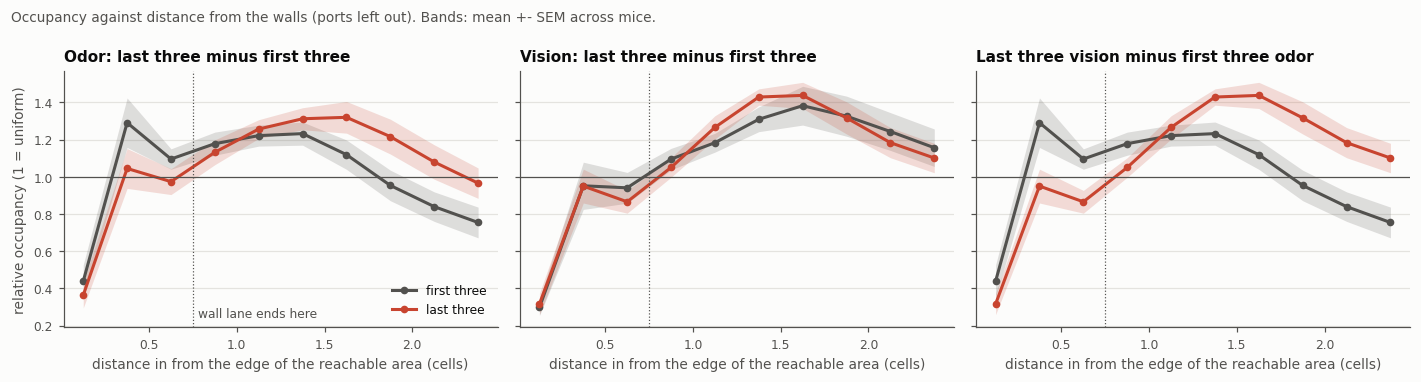

In [9]:
DIST_EDGES = np.arange(0, (REACH['x1'] - REACH['x0']) / 2 + 1, cfg.CELL_W / 4)
band = np.where(ports | (wall_dist <= 0), -1, np.digitize(wall_dist, DIST_EDGES) - 1)      # ports and unreachable bins left out

def wall_profile(keep):
    """Per mouse (rows), occupancy by distance from the nearest wall: mean density of the bins in each distance band."""
    return pd.DataFrame({m: [d[band == k].mean() for k in range(len(DIST_EDGES) - 1)] for m, d in per_mouse_maps(keep).items()}).T

fig, axes = plt.subplots(1, len(CHANGES), figsize=(13, 3.5), sharey=True)
mid_dist = (DIST_EDGES[:-1] + DIST_EDGES[1:]) / 2 / cfg.CELL_W
for ax, (name, (before, after)) in zip(axes, CHANGES.items()):
    for keep, color, label in ((before, MUTED, 'first three'), (after, '#c8442f', 'last three')):
        p = wall_profile(keep)
        ax.fill_between(mid_dist, p.mean() - p.sem(), p.mean() + p.sem(), color=color, alpha=0.18, lw=0)
        ax.plot(mid_dist, p.mean(), color=color, lw=2, marker='o', ms=4, label=label)
    ax.axvline(LANE / cfg.CELL_W, color=MUTED, lw=0.8, ls=':'); ax.axhline(1, color=MUTED, lw=0.8)
    ax.set(title=name, xlabel='distance in from the edge of the reachable area (cells)')
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].set_ylabel(RELATIVE); axes[0].legend()
axes[0].text(LANE / cfg.CELL_W + 0.03, 0.04, 'wall lane ends here', fontsize=8, color=MUTED, transform=axes[0].get_xaxis_transform())
fig.suptitle('Occupancy against distance from the walls (ports left out). Bands: mean +- SEM across mice.', x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

**Within an experiment the change is modest.** From the first three to the last three sessions:
- *Odor:* the nose spends less time outside the target grid (46% to 40%, 7/9 mice, p = 0.06) and more in the interior (62% to 69%, 7/9 mice, p = 0.05).
- *Vision:* no change (37% to 35% outside the grid).
- *Both:* less time with the nose at a port (2.9% to 1.6% in odor, 8/9 mice; 1.8% to 1.4% in vision, 7/9 mice).

**Across the whole history the shift is clear.** From the first three odor sessions to the last three vision sessions:
- time with the nose outside the target grid falls from 46% to 35% (8/9 mice);
- the wall lane falls from 35% to 26% (8/9 mice), along the side walls in every mouse (13% to 9%);
- time at the ports halves (2.9% to 1.4%, 9/9 mice);
- the interior rises from 62% to 72% (8/9 mice).

The map shows it as blue around the whole edge, deepest at the low-y end, and red across the grid, strongest just inside the two ends. In the profile, late-session occupancy is lower within a cell of the edge and higher everywhere beyond it.

## 5. Good sessions minus poor sessions

For each mouse and experiment, the three sessions with the most targets found minus the three with the fewest. This is not the same comparison as section 4: a mouse's best sessions are not all its latest ones.

finds  mean_session_number
experiment kind                                   
odor       best three   134.6                  7.0
           worst three  102.1                  4.5
vision     best three   155.6                  5.9
           worst three  123.7                  4.0

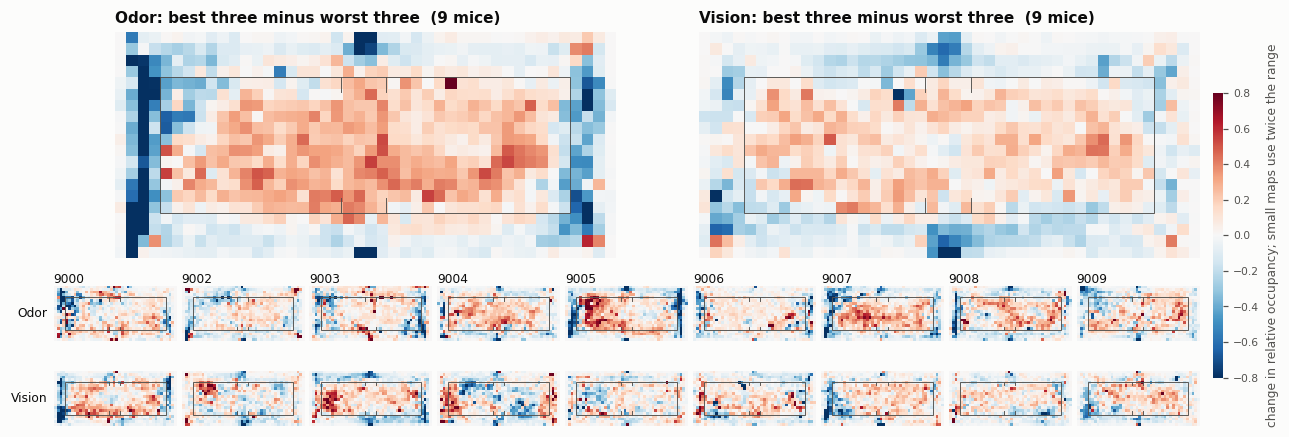

before  after  change  p (paired t) mice down
Odor: best three minus worst three   wall lane                 0.360  0.281  -0.079         0.002       8/9
                                        along the side walls   0.131  0.113  -0.018         0.054       7/9
                                        along the end walls    0.228  0.167  -0.061         0.003       8/9
                                     at the ports              0.026  0.019  -0.008         0.113       7/9
                                     interior                  0.612  0.699   0.087         0.002       0/9
                                     outside the target grid   0.468  0.384  -0.084         0.003       9/9
Vision: best three minus worst three wall lane                 0.280  0.243  -0.037         0.085       7/9
                                        along the side walls   0.109  0.083  -0.026         0.005       9/9
                                        along the end walls    0.171  0.160  -0.011         0.570       4/9
                                     at the ports              0.019  0.014  -0.004         0.022       7/9
                                     interior                  0.699  0.741   0.042         0.058       1/9
                                     outside the target grid   0.380  0.331  -0.050         0.030       8/9

In [10]:
rank = ses.groupby(['experiment', 'mouse']).finds.rank(method='first')
best = rank > ses.n_sessions - 3
worst = rank <= 3
QUALITY = {f'{EXP_LABEL[exp]}: best three minus worst three': ((ses.experiment == exp) & worst, (ses.experiment == exp) & best) for exp in EXPERIMENTS}

picked = ses.assign(kind=np.where(best, 'best three', np.where(worst, 'worst three', 'other')))
display(picked[picked.kind != 'other'].groupby(['experiment', 'kind']).agg(finds=('finds', 'mean'), mean_session_number=('session_num', 'mean')).round(1))
difference_figure(QUALITY)
quality_zones = pd.concat({name: zone_change(*keep) for name, keep in QUALITY.items()})
quality_zones

**In a mouse's best sessions its nose spends less time outside the target grid.**
- *Odor:* 38% of search time outside the grid in the three best sessions against 47% in the three worst, in all nine mice. Most of it is at the end walls (17% against 23%, 8/9 mice). The interior takes 70% against 61% (9/9 mice).
- *Vision:* the same direction, smaller: 33% against 38% outside the grid (8/9 mice, p = 0.03). The most consistent part is along the side walls (8% against 11%, 9/9 mice).

Best sessions come somewhat later than worst ones on average (session 7.0 against 4.5 in odor, 5.9 against 4.0 in vision), so part of this is experience.

## Summary

**The nose maps tell the same story as the body maps, and add one thing: how much searching is wasted.** With the nose outside the target grid nothing is being checked, and that is where the nose is for 42% of search time in the odor sessions and 36% in vision.

**Mice differ, and consistently.** Each mouse has its own nose map; its sessions resemble each other more than other mice's (9/9 mice in both experiments), and its departures from the average carry over from odor to vision. Time outside the grid ranges from a quarter to over half of the search, depending on the mouse.

**Last three sessions minus first three.**
- Within odor the nose moves into the grid somewhat (46% to 40% outside, 7/9 mice); within vision it does not.
- Over the whole history the shift is clear: 46% to 35% outside the grid (8/9 mice), with time at the ports halved.

**Good sessions minus poor sessions.** In the odor sessions the nose is outside the grid for 38% of the search in a mouse's best sessions against 47% in its worst, in every mouse; in vision 33% against 38% (8/9 mice).

**How the nose and centroid notebooks compare.**
- The direction of every effect is the same. Sessions agree closely too: the share of time the nose is outside the grid and the share the body is in the wall lane correlate 0.80 across sessions in odor and 0.76 in vision.
- The nose version is the more direct statement about search, because the outer ring is defined by the task: time there cannot find a target.
- The zones are not the same places in the two notebooks. The body's wall lane lies just inside the target-grid rectangle; the nose's lies mostly outside it. Compare directions and sizes of change, not the raw shares.

**Reading the results.**
- Less time outside the grid in good sessions does not show which causes which. Long, unsuccessful searches may themselves be spent nosing along the walls.
- Some time outside the grid is unavoidable: turning around at an end wall puts the nose there, each search starts at a port, and the ITI at the start of each search is spent leaving it. So the 36-42% is an upper bound on what could be recovered, not the amount that is wasted.
- The comparison across the whole history cannot separate experience from the change of cue, since every mouse ran vision after odor.
- "Search" here is the appetitive epoch, which starts when the mouse leaves the port and so includes the ITI. Notebooks 1-6 time a search from the start of the trial, when the target appears; that is about 5 minutes less per session.
- The SLEAP nose jumps on a small fraction of frames, which adds scatter to the per-session and per-mouse maps but not a direction.
- p-values are unadjusted, and the per-mouse difference maps are noisy; the zone shares are the more reliable summary.
- Excluded: the odor `o` and `t` shaping sessions and sessions beyond each mouse's ten.